In [ ]:
# Лабораторная работа 5

Saving cat.jpg to cat.jpg


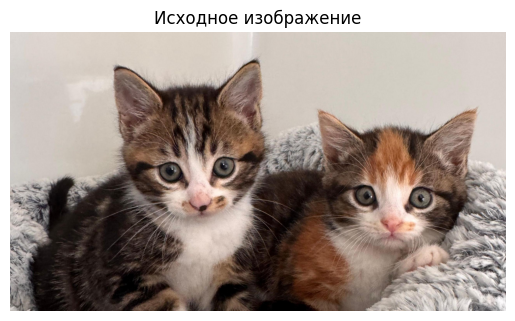

In [ ]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

filename = list(uploaded.keys())[0]

image = Image.open(filename)

plt.imshow(image)
plt.title("Исходное изображение")
plt.axis("off")
plt.show()

## 1. Преобразование изображения в оттенки серого

Операторы Собеля и Прюитта обычно применяются к чёрно-белому изображению.

Поэтому сначала нужно преобразовать изображение в оттенки серого.

В таком изображении каждый пиксель хранит не цвет RGB, а только яркость.

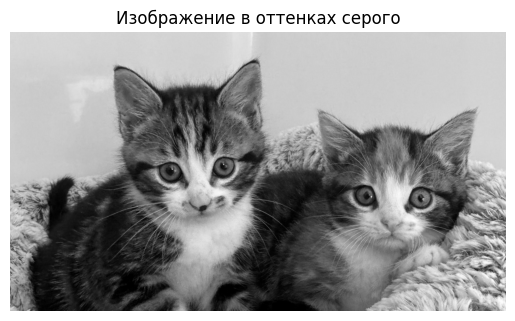

In [ ]:
gray_image = image.convert("L")

gray = np.array(gray_image)

plt.imshow(gray, cmap="gray")
plt.title("Изображение в оттенках серого")
plt.axis("off")
plt.show()



---

## 2. Оператор Собеля

Оператор Собеля используется для выделения границ на изображении.

Он ищет резкие изменения яркости.

Для этого используются два ядра:

* Gx - ищет изменения по горизонтали;
* Gy - ищет изменения по вертикали.

Ядро Gx:

```
-1  0  1
-2  0  2
-1  0  1
```
Ядро Gy:

```
-1 -2 -1
 0  0  0
 1  2  1
 ```

In [ ]:
sobel_gx = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

sobel_gy = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
])

print("Ядро Sobel Gx:")
print(sobel_gx)

print("\nЯдро Sobel Gy:")
print(sobel_gy)

Ядро Sobel Gx:
[[-1  0  1]
 [-2  0  2]
 [-1  0  1]]

Ядро Sobel Gy:
[[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]




---

## 3. Функция свёртки

Свёртка - это операция, при которой ядро проходит по изображению.

Для каждого участка изображения размером 3×3 выполняется умножение на ядро.

Затем все полученные значения складываются.

Так получается новое значение пикселя.

In [ ]:
def convolution(image, kernel):
    height, width = image.shape
    k_height, k_width = kernel.shape

    output = np.zeros((height - 2, width - 2))

    for i in range(height - 2):
        for j in range(width - 2):
            region = image[i:i+3, j:j+3]
            value = np.sum(region * kernel)
            output[i, j] = value

    return output



---
## 4. Применение оператора Собеля

Сначала применяем ядро Gx.

Оно выделяет вертикальные границы.

Затем применяем ядро Gy.

Оно выделяет горизонтальные границы.

После этого вычисляем модуль градиента:

G = sqrt(Gx² + Gy²)

Модуль градиента показывает общую силу границы.

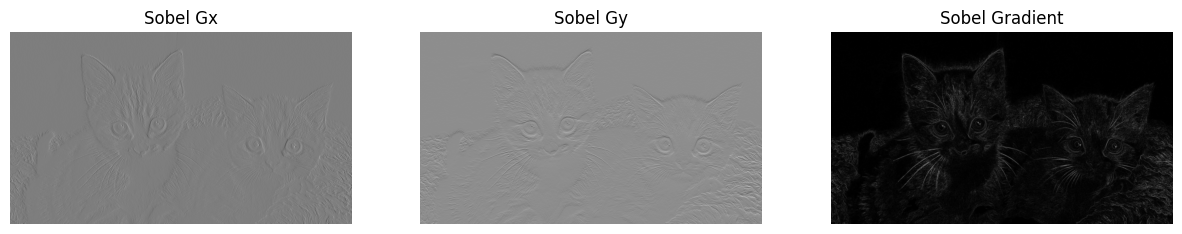

In [ ]:
sobel_x = convolution(gray, sobel_gx)
sobel_y = convolution(gray, sobel_gy)

sobel_gradient = np.sqrt(sobel_x ** 2 + sobel_y ** 2)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(sobel_x, cmap="gray")
plt.title("Sobel Gx")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sobel_y, cmap="gray")
plt.title("Sobel Gy")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sobel_gradient, cmap="gray")
plt.title("Sobel Gradient")
plt.axis("off")

plt.show()



---
## 5. Оператор Прюитта

Оператор Прюитта тоже используется для выделения границ.

Он похож на оператор Собеля.

Главное отличие в ядрах.

У Прюитта все коэффициенты имеют одинаковый вес.

Ядро Prewitt Gx:

```
-1  0  1
-1  0  1
-1  0  1
```

Ядро Prewitt Gy:
```
-1 -1 -1
 0  0  0
 1  1  1
 ```


In [ ]:
prewitt_gx = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])

prewitt_gy = np.array([
    [-1, -1, -1],
    [0, 0, 0],
    [1, 1, 1]
])

print("Ядро Prewitt Gx:")
print(prewitt_gx)

print("\nЯдро Prewitt Gy:")
print(prewitt_gy)

Ядро Prewitt Gx:
[[-1  0  1]
 [-1  0  1]
 [-1  0  1]]

Ядро Prewitt Gy:
[[-1 -1 -1]
 [ 0  0  0]
 [ 1  1  1]]




---

## 6. Применение оператора Прюитта

Теперь применим оператор Прюитта к изображению.

Как и в операторе Собеля:

* сначала вычисляется Gx;
* затем вычисляется Gy;
* затем считается общий модуль градиента.





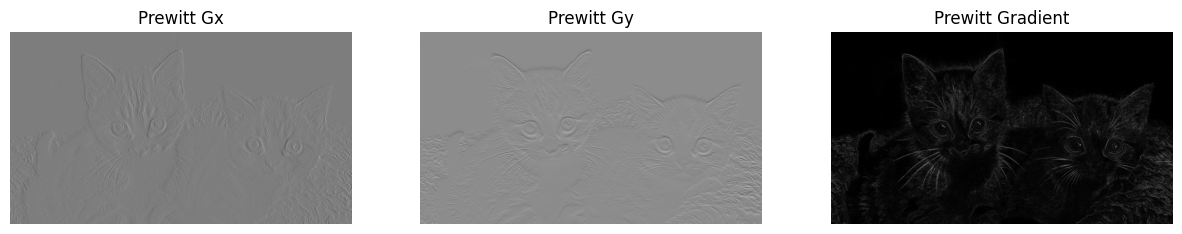

In [ ]:
prewitt_x = convolution(gray, prewitt_gx)
prewitt_y = convolution(gray, prewitt_gy)

prewitt_gradient = np.sqrt(prewitt_x ** 2 + prewitt_y ** 2)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(prewitt_x, cmap="gray")
plt.title("Prewitt Gx")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(prewitt_y, cmap="gray")
plt.title("Prewitt Gy")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(prewitt_gradient, cmap="gray")
plt.title("Prewitt Gradient")
plt.axis("off")

plt.show()



---
## 7. Сравнение операторов Собеля и Прюитта

Оператор Собеля и оператор Прюитта выполняют похожую задачу.

Оба оператора выделяют границы на изображении.

Но между ними есть отличие.

Оператор Собеля использует коэффициент 2 в центральной строке или центральном столбце.

Из-за этого он сильнее учитывает центральные пиксели.

Оператор Прюитта использует одинаковые коэффициенты.

Поэтому он проще, но может хуже подавлять шум.


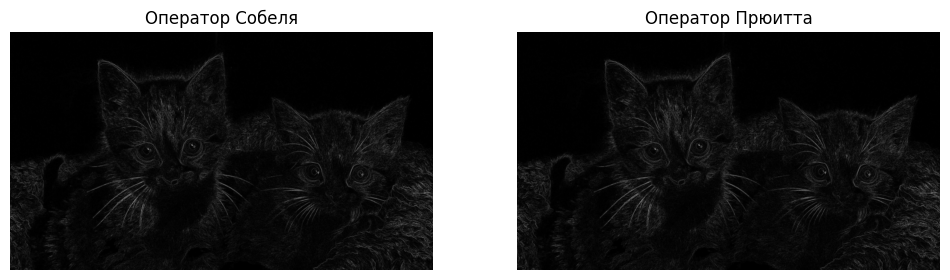

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(sobel_gradient, cmap="gray")
plt.title("Оператор Собеля")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(prewitt_gradient, cmap="gray")
plt.title("Оператор Прюитта")
plt.axis("off")

plt.show()

### Вывод по сравнению Собеля и Прюитта

Оператор Собеля обычно выделяет границы более чётко.

Он лучше подавляет небольшие шумы, потому что центральные пиксели имеют больший вес.

Оператор Прюитта тоже выделяет границы, но результат может быть немного более грубым.

В целом, Собель чаще используется на практике, потому что даёт более устойчивый результат.



---

## 8. Размытие Гаусса

Размытие Гаусса применяется для сглаживания изображения.

Оно уменьшает шум и мелкие детали.

После размытия оператор выделения границ может работать лучше, потому что случайные шумы меньше мешают обработке.

Для размытия используем простое ядро Гаусса 3×3:
```
1  2  1
2  4  2
1  2  1
```

Чтобы сумма коэффициентов была равна 1, делим ядро на 16.

In [ ]:
gaussian_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
]) / 16

print("Ядро Гаусса:")
print(gaussian_kernel)

Ядро Гаусса:
[[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]


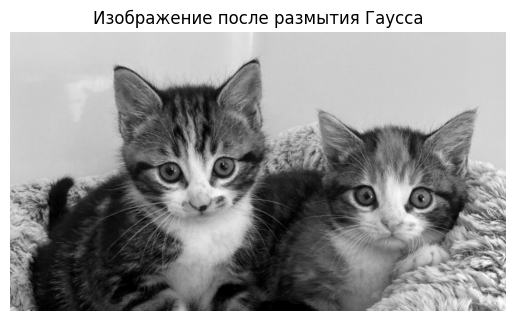

In [ ]:
blurred = convolution(gray, gaussian_kernel)

plt.imshow(blurred, cmap="gray")
plt.title("Изображение после размытия Гаусса")
plt.axis("off")
plt.show()

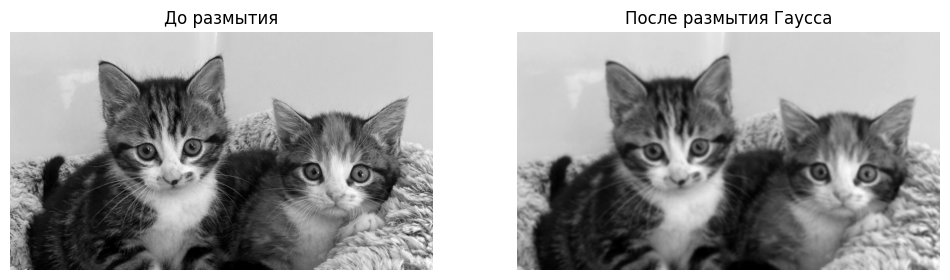

In [ ]:
from PIL import ImageFilter

blurred_image = gray_image.filter(ImageFilter.GaussianBlur(radius=5))

blurred = np.array(blurred_image)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("До размытия")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred, cmap="gray")
plt.title("После размытия Гаусса")
plt.axis("off")

plt.show()



---
## 9. Повторное применение оператора Собеля

Теперь применим оператор Собеля к размытому изображению.

Из-за размытия размер изображения уже немного уменьшился.

Но это нормально, потому что наша функция свёртки работает без padding.


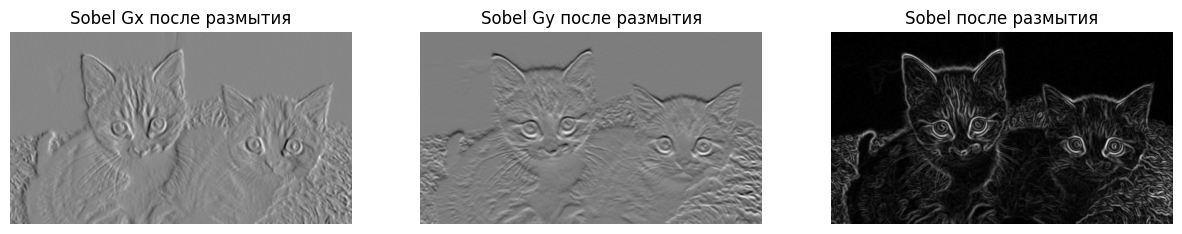

In [ ]:
sobel_blur_x = convolution(blurred, sobel_gx)
sobel_blur_y = convolution(blurred, sobel_gy)

sobel_blur_gradient = np.sqrt(sobel_blur_x ** 2 + sobel_blur_y ** 2)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(sobel_blur_x, cmap="gray")
plt.title("Sobel Gx после размытия")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sobel_blur_y, cmap="gray")
plt.title("Sobel Gy после размытия")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sobel_blur_gradient, cmap="gray")
plt.title("Sobel после размытия")
plt.axis("off")

plt.show()



---
## Итоговый вывод

В данной практической работе были применены два оператора выделения границ: оператор Собеля и оператор Прюитта.

Сначала изображение было загружено и преобразовано в оттенки серого.

Затем были заданы ядра Gx и Gy для оператора Собеля.

С помощью свёртки были получены горизонтальные и вертикальные изменения яркости.

После этого был вычислен модуль градиента, который показывает силу границы.

Оператор Собеля показал более чёткое выделение границ, потому что его ядра сильнее учитывают центральные пиксели.

Затем был реализован оператор Прюитта.

Он также выделяет границы, но результат может быть немного менее точным и более чувствительным к шуму.

После этого к изображению было применено размытие Гаусса.

Размытие позволило уменьшить шум и сгладить мелкие детали.

При повторном применении оператора Собеля к размытому изображению основные границы стали более чистыми.

Однако некоторые мелкие детали могли стать менее заметными.

Таким образом, предварительная фильтрация с помощью размытия Гаусса улучшает качество выделения основных границ, особенно если изображение содержит шум.

Но если размытие слишком сильное, то мелкие важные детали могут исчезнуть.
